##### Citation Info
@InProceedings{Gushchin_2026_CVPR,
    author    = {Gushchin, Aleksandr and Abud, Khaled and Shumitskaya, Ekaterina and Filippov, Artem and Bychkov, Georgii and Lavrushkin, Sergey and Erofeev, Mikhail and Antsiferova, Anastasia and Chen, Changsheng and Tan, Shunquan and Timofte, Radu and Vatolin, Dmitriy and Song, Chuanbiao and Yu, Zijian and Tan, Hao and Lan, Jun and Yang, Zhiqiang and Tang, Yongwei and Wu, Zhiqiang and Seow, Jia Wen and Koay, Hong Vin and Ren, Haodong and Xu, Feng and Chen, Shuai and Xia, Ruiyang and Zhang, Qi and Xu, Yaowen and Zou, Zhaofan and Sun, Hao and Lu, Dagong and Yao, Mufeng and Xu, Xinlei and Wu, Fei and Guo, Fengjun and Luo, Cong and Sharma, Hardik and Negi, Aashish and Shaily, Prateek and Kumar, Jayant and Chaudhary, Sachin and Dudhane, Akshay and Hambarde, Praful and Shukla, Amit and Tu, Zhilin and Li, Fengpeng and Zhang, Jiamin and Fei, Jianwei and Li, Kemou and Wu, Haiwei and Benjdira, Bilel and Ali, Anas M. and Boulila, Wadii and Qu, Chenfan and Li, Junchi},
    title     = {NTIRE 2026 Challenge on Robust AI-Generated Image Detection in the Wild},
    booktitle = {Proceedings of the IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR) Workshops},
    month     = {June},
    year      = {2026},
    pages     = {1895-1913}
}


In [7]:
import torch
import torchvision

# check NVIDIA GPU available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [8]:
# Set up image transforms, datasets, and data loaders

from torch.utils.data import DataLoader
from torchvision import transforms
from official_augmentations import OfficialDistortions
from aigendet_dataset import AIGenDetDataset
from clip_transforms import CLIPTransform
from transformers import CLIPImageProcessor

# CLIP default transform (no augmentations yet)
processor = CLIPImageProcessor.from_pretrained("openai/clip-vit-base-patch32")
transform = CLIPTransform(processor)

# On half the training images, apply 1-3 official distortions before normalization.
official_distortions = OfficialDistortions(max_distortions=3, num_levels=5)
augmentation = transforms.RandomApply([official_distortions], p=0.50)
train_transform = CLIPTransform(processor, augmentation=augmentation)

batch_size = 32

train_path = "../data/train"
train_shard_nums = [0, 5] # list of training shards to use (0-5)
train = AIGenDetDataset(train_path, train_shard_nums, transform=train_transform)
val = AIGenDetDataset(
    image_dir="../data/val/val/val_images",
    labels_csv="../data/val/val/val_labels.csv",
    transform=transform,
)
val_hard = AIGenDetDataset(
    image_dir="../data/val/val_hard/val_images_hard",
    labels_csv="../data/val/val_hard/val_hard_labels.csv",
    transform=transform,
)
test = AIGenDetDataset(
    image_dir="../data/test/test_images",
    labels_csv="../data/test/test_labels.csv",
    transform=transform,
)

trainloader = DataLoader(train, batch_size=batch_size, shuffle=True, num_workers=8, pin_memory=True, persistent_workers=True)
valloader = DataLoader(val, batch_size=batch_size, shuffle=False, num_workers=8, pin_memory=True, persistent_workers=True)
val_hardloader = DataLoader(val_hard, batch_size=batch_size, shuffle=False, num_workers=8, pin_memory=True, persistent_workers=True)

# Creating this loader does not run test evaluation.
testloader = DataLoader(test, batch_size=batch_size, shuffle=False, num_workers=8, pin_memory=True, persistent_workers=True)


Found 2 shards, 77643 images in total.
Found 10000 images in ../data/val/val/val_images.
Found 2500 images in ../data/val/val_hard/val_images_hard.
Found 2500 images in ../data/test/test_images.


In [9]:
# Set up CLIP encoder
from transformers import CLIPVisionModel

encoder = CLIPVisionModel.from_pretrained("openai/clip-vit-base-patch32")

# Freeze all encoder parameters
for parameter in encoder.parameters():
    parameter.requires_grad = False

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 19397.77it/s]
[transformers] CLIPVisionModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
visual_projection.weight                                     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weigh

In [10]:
# Define the binary classifier model
import torch.nn as nn

class CLIPBinaryClassifier(nn.Module):
    def __init__(self, encoder):
        super(CLIPBinaryClassifier, self).__init__()
        self.encoder = encoder
        self.classifier = nn.Linear(encoder.config.hidden_size, 2)
        

    def forward(self, x):
        # Pass the input through the encoder
        outputs = self.encoder(x)
        # Get the pooled output
        pooled_output = outputs.pooler_output
        # Pass the pooled output through the classifier
        logits = self.classifier(pooled_output)
        return logits

In [ ]:
# Set up model
model = CLIPBinaryClassifier(encoder)
model.to(device)

CLIPBinaryClassifier(
  (encoder): CLIPVisionModel(
    (embeddings): CLIPVisionEmbeddings(
      (patch_embedding): Conv2d(3, 768, kernel_size=(32, 32), stride=(32, 32), bias=False)
      (position_embedding): Embedding(50, 768)
    )
    (pre_layrnorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
    (encoder): CLIPEncoder(
      (layers): ModuleList(
        (0-11): 12 x CLIPEncoderLayer(
          (self_attn): CLIPAttention(
            (k_proj): Linear(in_features=768, out_features=768, bias=True)
            (v_proj): Linear(in_features=768, out_features=768, bias=True)
            (q_proj): Linear(in_features=768, out_features=768, bias=True)
            (out_proj): Linear(in_features=768, out_features=768, bias=True)
          )
          (layer_norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
          (mlp): CLIPMLP(
            (activation_fn): QuickGELUActivation()
            (fc1): Linear(in_features=768, out_features=3072, bia

In [12]:
# set up optimizer

import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam([
    {"params": model.classifier.parameters(), "lr": 1e-4},
    {"params": model.encoder.encoder.layers[-1].parameters(), "lr": 1e-5}
])

In [ ]:
# Train/eval loop
from sklearn.metrics import roc_auc_score

best_roc_auc = float('-inf')
miss_count = 0
max_misses = 5

for epoch in range(50):
    model.train()

    running_loss = 0.0

    for i, batch in enumerate(trainloader, 0):
        images = batch["image"].to(device)
        binary_labels = batch["label"].to(device)
        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, binary_labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        if i % 250 == 249:    # print every 250 mini-batches
            print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 250:.6f}')
            running_loss = 0.0
    print(f'Finished epoch {epoch + 1}')
    
    # Validation
    model.eval()
    y_true, y_ai_probability = [], []
    y_true_hard, y_ai_probability_hard = [], []

    with torch.no_grad():
        for batch in valloader:
            images = batch["image"].to(device)
            ai_probability = model(images).softmax(dim=1)[:, 1]

            y_true.extend(batch["label"].tolist())
            y_ai_probability.extend(ai_probability.cpu().tolist())

    val_roc_auc = roc_auc_score(y_true, y_ai_probability)
    print(f"Validation ROC AUC: {val_roc_auc:.6f}")

    with torch.no_grad():
            for batch in val_hardloader:
                images = batch["image"].to(device)
                ai_probability = model(images).softmax(dim=1)[:, 1]
    
                y_true_hard.extend(batch["label"].tolist())
                y_ai_probability_hard.extend(ai_probability.cpu().tolist())
    
    val_hard_roc_auc = roc_auc_score(y_true_hard, y_ai_probability_hard)
    print(f"Hard Validation ROC AUC: {val_hard_roc_auc:.6f}")

    if val_roc_auc > best_roc_auc:
        best_roc_auc = val_roc_auc
        miss_count = 0
        torch.save(model, "../models/CLIPClassifier.pth")
    else:
        miss_count += 1
        if miss_count >= max_misses:
            print("ROC AUC stopped improving, stopping early.")
            break

print('Finished Training')

[1,   250] loss: 0.486406
[1,   500] loss: 0.342055
[1,   750] loss: 0.307918
[1,  1000] loss: 0.305221
[1,  1250] loss: 0.279263
[1,  1500] loss: 0.273573
[1,  1750] loss: 0.261254
[1,  2000] loss: 0.264426
[1,  2250] loss: 0.247723
Finished epoch 1
Validation ROC AUC: 0.905181
[2,   250] loss: 0.231924
[2,   500] loss: 0.229066
[2,   750] loss: 0.224573
[2,  1000] loss: 0.211126
[2,  1250] loss: 0.214105
[2,  1500] loss: 0.209972
[2,  1750] loss: 0.219992
[2,  2000] loss: 0.206663
[2,  2250] loss: 0.221886
Finished epoch 2
Validation ROC AUC: 0.920572
[3,   250] loss: 0.188825
[3,   500] loss: 0.187373
[3,   750] loss: 0.181344
[3,  1000] loss: 0.193722
[3,  1250] loss: 0.188697
[3,  1500] loss: 0.181349
[3,  1750] loss: 0.177864
[3,  2000] loss: 0.172040
[3,  2250] loss: 0.181805
Finished epoch 3
Validation ROC AUC: 0.922108
[4,   250] loss: 0.158495
[4,   500] loss: 0.161990
[4,   750] loss: 0.150939
[4,  1000] loss: 0.166828
[4,  1250] loss: 0.160603
[4,  1500] loss: 0.155376
[4, 


Overall: 10000 images
              precision    recall  f1-score   support

        Real      0.897     0.785     0.837      5000
AI-generated      0.809     0.909     0.856      5000

    accuracy                          0.847     10000
   macro avg      0.853     0.847     0.847     10000
weighted avg      0.853     0.847     0.847     10000

Confusion matrix (rows: actual, columns: predicted; order: Real, AI-generated):
[[3927 1073]
 [ 453 4547]]
Balanced accuracy: 0.8474
Brier score (lower is better): 0.1248
Log loss (lower is better): 0.5707
ROC-AUC (higher is better): 0.935232

Clean: 5000 images
              precision    recall  f1-score   support

        Real      0.911     0.822     0.864      2500
AI-generated      0.838     0.919     0.877      2500

    accuracy                          0.871      5000
   macro avg      0.874     0.871     0.870      5000
weighted avg      0.874     0.871     0.870      5000

Confusion matrix (rows: actual, columns: predicted; order: R

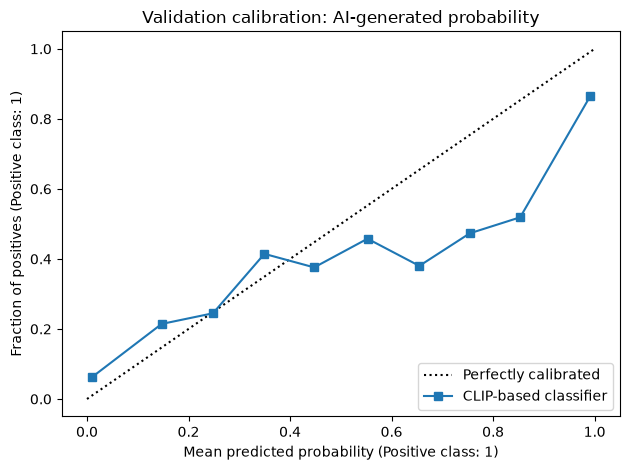

In [14]:
# Get detailed metrics for the current model on the validation set
model = torch.load('../models/CLIPClassifier.pth', map_location=device, weights_only=False)

import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    brier_score_loss,
    log_loss,
    roc_auc_score,
)

y_true, y_pred, y_ai_probability, is_distorted = [], [], [], []

model.eval()
with torch.no_grad():
    for batch in valloader:
        images = batch["image"].to(device)
        outputs = model(images)
        probabilities = outputs.softmax(dim=1)
        predictions = probabilities.argmax(dim=1)

        y_true.extend(batch["label"].to(device).tolist())
        y_pred.extend(predictions.tolist())
        # Class 1 is AI-generated; use its probability for every image.
        y_ai_probability.extend(probabilities[:, 1].tolist())
        is_distorted.extend(batch["is_distorted"].tolist())

# Keep the labels, predictions, scores, and distortion flags aligned.
y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)
y_ai_probability = np.asarray(y_ai_probability)
is_distorted = np.asarray(is_distorted)

# Classification uses the existing argmax decision (equivalent to threshold 0.5,
# with ties assigned to Real). ROC AUC uses continuous AI probabilities.
for subset_name, mask in [
    ("Overall", np.ones(len(y_true), dtype=bool)),
    ("Clean", is_distorted == 0),
    ("Distorted (robustness)", is_distorted == 1),
]:
    print(f"\n{subset_name}: {mask.sum()} images")
    if not mask.any():
        print("No images in this subset; skipping metrics.")
        continue

    labels = y_true[mask]
    predicted = y_pred[mask]
    scores = y_ai_probability[mask]
    print(classification_report(
        labels,
        predicted,
        labels=[0, 1],
        target_names=["Real", "AI-generated"],
        digits=3,
        zero_division=0,
    ))
    print("Confusion matrix (rows: actual, columns: predicted; order: Real, AI-generated):")
    print(confusion_matrix(labels, predicted, labels=[0, 1]))
    print(f"Balanced accuracy: {balanced_accuracy_score(labels, predicted):.4f}")
    print(f"Brier score (lower is better): {brier_score_loss(labels, scores):.4f}")
    print(f"Log loss (lower is better): {log_loss(labels, scores, labels=[0, 1]):.4f}")
    if len(np.unique(labels)) == 2:
        print(f"ROC-AUC (higher is better): {roc_auc_score(labels, scores):.6f}")
    else:
        print("ROC-AUC is undefined: this subset contains only one class.")

# Near the diagonal means predicted AI probabilities match observed AI frequencies.
CalibrationDisplay.from_predictions(
    y_true,
    y_ai_probability,
    n_bins=10,
    strategy="uniform",
    name="CLIP-based classifier",
)
plt.title("Validation calibration: AI-generated probability")
plt.tight_layout()
plt.show()



Overall: 2500 images
              precision    recall  f1-score   support

        Real      0.776     0.728     0.751      1250
AI-generated      0.744     0.790     0.766      1250

    accuracy                          0.759      2500
   macro avg      0.760     0.759     0.759      2500
weighted avg      0.760     0.759     0.759      2500

Confusion matrix (rows: actual, columns: predicted; order: Real, AI-generated):
[[910 340]
 [263 987]]
Balanced accuracy: 0.7588
Brier score (lower is better): 0.1942
Log loss (lower is better): 0.8849
ROC-AUC (higher is better): 0.854466

Clean: 1250 images
              precision    recall  f1-score   support

        Real      0.832     0.763     0.796       625
AI-generated      0.781     0.846     0.813       625

    accuracy                          0.805      1250
   macro avg      0.807     0.805     0.804      1250
weighted avg      0.807     0.805     0.804      1250

Confusion matrix (rows: actual, columns: predicted; order: Real, 

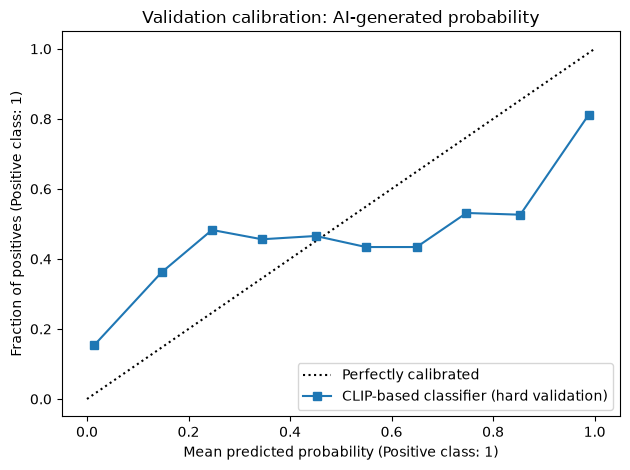

In [15]:
# Get detailed metrics for the current model on the hard validation set
model = torch.load('../models/CLIPClassifier.pth', map_location=device, weights_only=False)

import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    brier_score_loss,
    log_loss,
    roc_auc_score,
)

y_true, y_pred, y_ai_probability, is_distorted = [], [], [], []

model.eval()
with torch.no_grad():
    for batch in val_hardloader:
        images = batch["image"].to(device)
        outputs = model(images)
        probabilities = outputs.softmax(dim=1)
        predictions = probabilities.argmax(dim=1)

        y_true.extend(batch["label"].to(device).tolist())
        y_pred.extend(predictions.tolist())
        # Class 1 is AI-generated; use its probability for every image.
        y_ai_probability.extend(probabilities[:, 1].tolist())
        is_distorted.extend(batch["is_distorted"].tolist())

# Keep the labels, predictions, scores, and distortion flags aligned.
y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)
y_ai_probability = np.asarray(y_ai_probability)
is_distorted = np.asarray(is_distorted)

# Classification uses the existing argmax decision (equivalent to threshold 0.5,
# with ties assigned to Real). ROC AUC uses continuous AI probabilities.
for subset_name, mask in [
    ("Overall", np.ones(len(y_true), dtype=bool)),
    ("Clean", is_distorted == 0),
    ("Distorted (robustness)", is_distorted == 1),
]:
    print(f"\n{subset_name}: {mask.sum()} images")
    if not mask.any():
        print("No images in this subset; skipping metrics.")
        continue

    labels = y_true[mask]
    predicted = y_pred[mask]
    scores = y_ai_probability[mask]
    print(classification_report(
        labels,
        predicted,
        labels=[0, 1],
        target_names=["Real", "AI-generated"],
        digits=3,
        zero_division=0,
    ))
    print("Confusion matrix (rows: actual, columns: predicted; order: Real, AI-generated):")
    print(confusion_matrix(labels, predicted, labels=[0, 1]))
    print(f"Balanced accuracy: {balanced_accuracy_score(labels, predicted):.4f}")
    print(f"Brier score (lower is better): {brier_score_loss(labels, scores):.4f}")
    print(f"Log loss (lower is better): {log_loss(labels, scores, labels=[0, 1]):.4f}")
    if len(np.unique(labels)) == 2:
        print(f"ROC-AUC (higher is better): {roc_auc_score(labels, scores):.6f}")
    else:
        print("ROC-AUC is undefined: this subset contains only one class.")

# Near the diagonal means predicted AI probabilities match observed AI frequencies.
CalibrationDisplay.from_predictions(
    y_true,
    y_ai_probability,
    n_bins=10,
    strategy="uniform",
    name="CLIP-based classifier (hard validation)",
)
plt.title("Validation calibration: AI-generated probability")
plt.tight_layout()
plt.show()
